# The Bookstore Intelligence Mission
Business Data and Text Mining | Assignment 2 | Web scraping `books.toscrape.com`

## Mission 1 - Reconnaissance
| Data | HTML tag / class | Notes |
|---|---|---|
| Title | `article.product_pod > h3 > a` (`title` attribute) | Visible text is truncated, so read the attribute |
| Price | `p.price_color` | Text like "£51.77" |
| Rating | `p.star-rating` (2nd class) | Word such as `Three`, mapped to 1-5 |
| Availability | `p.instock.availability` | Text "In stock" |

In [1]:
%pip install requests beautifulsoup4 pandas numpy matplotlib


  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp312-cp312-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 1.9 MB/s eta 0:00:05
   ----- ---------------------------------- 1.3/9.3 MB 2.7 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.3 MB 3.7 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.3 MB 4.0 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from urllib.parse import urljoin

BASE_URL = "https://books.toscrape.com/catalogue/page-{}.html"
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

## Mission 2 - Capture the data (one page)

In [3]:
def scrape_page(url):
    response = requests.get(url, timeout=15)
    if response.status_code != 200:
        return None
    response.encoding = "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")
    books = []
    for card in soup.find_all("article", class_="product_pod"):
        link = card.h3.a
        books.append({
            "Title": link["title"],
            "Price": float(card.find("p", class_="price_color").text.replace("£", "").strip()),
            "Rating": RATING_MAP[card.find("p", class_="star-rating")["class"][1]],
            "Availability": card.find("p", class_="instock availability").text.strip(),
            "URL": urljoin(url, link["href"]),
        })
    return books

first_page = pd.DataFrame(scrape_page(BASE_URL.format(1)))
first_page.head()

,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


## Mission 3 - Scale the operation (loop over pages)

In [4]:
def scrape_catalogue(n_pages=None):
    all_books, page = [], 1
    while n_pages is None or page <= n_pages:
        books = scrape_page(BASE_URL.format(page))
        if not books:
            break
        all_books.extend(books)
        print(f"Page {page}: {len(books)} books")
        page += 1
    return pd.DataFrame(all_books)

df = scrape_catalogue(5)          # 3 = base task, 5 = Bonus 1, None = Boss Level
df.to_csv("competitor_books.csv", index=False)
print(df.shape)
df.head()

Page 1: 20 books
Page 2: 20 books
Page 3: 20 books
Page 4: 20 books
Page 5: 20 books
(100, 5)


,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         100 non-null    str    
 1   Price         100 non-null    float64
 2   Rating        100 non-null    int64  
 3   Availability  100 non-null    str    
 4   URL           100 non-null    str    
dtypes: float64(1), int64(1), str(3)
memory usage: 4.0 KB


## Mission 4 - Intelligence analysis

In [6]:
print("1. Most expensive:", df.loc[df["Price"].idxmax(), ["Title", "Price"]].to_dict())
print("2. Cheapest:", df.loc[df["Price"].idxmin(), ["Title", "Price"]].to_dict())
print(f"3. Average price: £{df['Price'].mean():.2f}")
print("4. 5-star books:", (df["Rating"] == 5).sum())
print(f"5. % in stock: {df['Availability'].str.contains('In stock').mean() * 100:.1f}%")

1. Most expensive: {'Title': 'The Death of Humanity: and the Case for Life', 'Price': 58.11}
2. Cheapest: {'Title': 'Patience', 'Price': 10.16}
3. Average price: £34.56
4. 5-star books: 19
5. % in stock: 100.0%


In [7]:
# 6. Top 5 highest-rated (ties broken by lower price)
df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)[["Title", "Rating", "Price"]]

,Title,Rating,Price
81,Princess Between Worlds (Wide-Awake Princess #5),5,13.34
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",5,13.61
34,Sophie's World,5,15.94
54,Thirst,5,17.27
12,Set Me Free,5,17.46


In [8]:
# 7. Cheapest 5-star book
five = df[df["Rating"] == 5]
five.loc[five["Price"].idxmin(), ["Title", "Price"]]

Title    Princess Between Worlds (Wide-Awake Princess #5)
Price                                               13.34
Name: 81, dtype: object

## Bonus 3 and 4 - Rating counts and bar chart

Rating
1    22
2    19
3    22
4    18
5    19
Name: count, dtype: int64


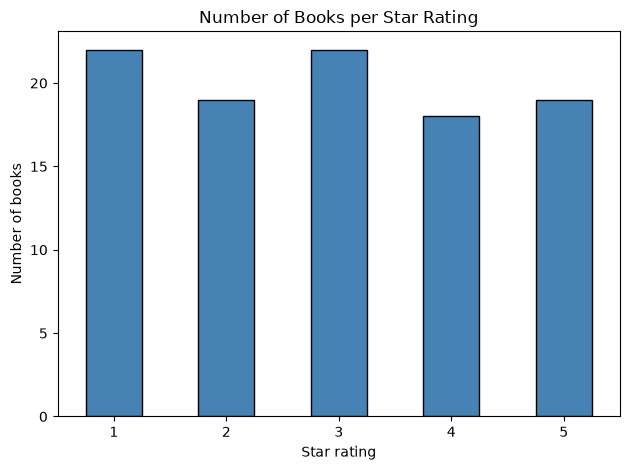

In [9]:
counts = df["Rating"].value_counts().sort_index()
print(counts)
counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of Books per Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Number of books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("rating_counts.png")
plt.show()

## Final Challenge - CEO has £100
Maximise total star rating without spending more than £100, using each book at most once.
This is a 0/1 knapsack problem, solved exactly with dynamic programming (prices in pence).

In [10]:
BUDGET = 10000
costs = (df["Price"] * 100).round().astype(int).to_numpy()
values = df["Rating"].to_numpy()
n = len(df)
dp = np.zeros(BUDGET + 1, dtype=int)
keep = np.zeros((n, BUDGET + 1), dtype=bool)
for i in range(n):
    c, v = costs[i], values[i]
    if c > BUDGET:
        continue
    cand = dp[: BUDGET + 1 - c] + v
    better = cand > dp[c:]
    keep[i, c:] = better
    dp[c:] = np.where(better, cand, dp[c:])

chosen, cap = [], BUDGET
for i in range(n - 1, -1, -1):
    if keep[i, cap]:
        chosen.append(i)
        cap -= costs[i]

picks = df.iloc[chosen][["Title", "Price", "Rating"]]
print(picks.to_string(index=False))
print(f"Total cost: £{picks['Price'].sum():.2f} | Total rating score: {picks['Rating'].sum()} | Books: {len(picks)}")

                                                                              Title  Price  Rating
Mama Tried: Traditional Italian Cooking for the Screwed, Crude, Vegan, and Tattooed  14.02       4
                                                                           Patience  10.16       3
                                   Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
  Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                            Untitled Collection: Sabbath Poems 2014  14.27       4
                                                                     Sophie's World  15.94       5
                                                                        Set Me Free  17.46       5
Total cost: £98.80 | Total rating score: 31 | Books: 7


## Mission 6 - Business recommendation

I would prioritize 4-5 star books priced below the average of £34.56, because they make up a healthy share of the catalogue and pair strong customer satisfaction with low cost. Since 100% of books are in stock, availability is not a differentiator, so we should compete on price and rating.